# 03 — Geometry-driven scenarios, rays, blockage, and system channels

**Purpose.** Connect topology, scenario large-scale state, cluster/ray generation,
antenna coefficients, blockage, and OFDM. The supported RMa, UMa, UMi, InH, and
InF models are snapshot models; temporal blocker birth/death is intentionally out
of scope.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Generate a topology and derive link geometry

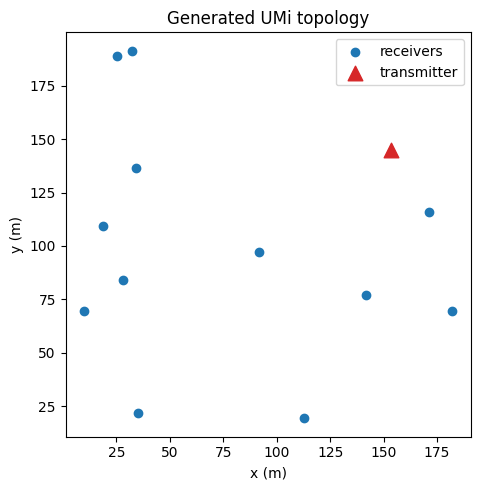

3-D link-distance range (m): (np.float64(34.95), np.float64(171.08))


In [2]:
from channel_dataset.channels.wireless import (
    ChannelSamplingRequest,
    RectangularTopologyConfig,
    RectangularTopologyGenerator,
    compute_link_geometry,
)

request = ChannelSamplingRequest(1, 4, 2_000.0, execution, execution.random_stream(3301), "umi-system")
topology = RectangularTopologyGenerator(
    RectangularTopologyConfig(
        num_tx=1,
        num_rx=12,
        width_m=200.0,
        length_m=200.0,
        tx_height_m=10.0,
        rx_height_m=1.5,
        rx_speed_mps=3.0,
        indoor_probability=0.0,
    )
).generate(request)
geometry = compute_link_geometry(topology)

assert geometry.shape == (1, 12, 1)
assert torch.all(geometry.distance_3d_m > 0.0)

tx = as_numpy(topology.tx_positions_m[0])
rx = as_numpy(topology.rx_positions_m[0])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(rx[:, 0], rx[:, 1], label="receivers", color="tab:blue")
ax.scatter(tx[:, 0], tx[:, 1], label="transmitter", marker="^", s=110, color="tab:red")
ax.set(title="Generated UMi topology", xlabel="x (m)", ylabel="y (m)", aspect="equal")
ax.legend()
fig.tight_layout()
plt.show()
print("3-D link-distance range (m):", tuple(np.round([as_numpy(geometry.distance_3d_m).min(), as_numpy(geometry.distance_3d_m).max()], 2)))

## 2. Compare the supported scenario configurations

In [3]:
from channel_dataset.channels.wireless import ScenarioConfig, create_scenario

scenario_configs = [
    ScenarioConfig("RMa", 2.0e9),
    ScenarioConfig("UMa", 3.5e9),
    ScenarioConfig("UMi", 3.5e9),
    ScenarioConfig("InH", 6.0e9, 120.0, 50.0, 3.0),
    ScenarioConfig("InF", 28.0e9, 100.0, 50.0, 10.0, 0.4, 5.0),
]
print("name | carrier (GHz) | standard")
for config in scenario_configs:
    scenario = create_scenario(config)
    print(f"{scenario.name:4s} | {config.carrier_frequency_hz / 1e9:13.1f} | TR 38.901 V16.1.0")

name | carrier (GHz) | standard
RMa  |           2.0 | TR 38.901 V16.1.0
UMa  |           3.5 | TR 38.901 V16.1.0
UMi  |           3.5 | TR 38.901 V16.1.0
InH  |           6.0 | TR 38.901 V16.1.0
InF  |          28.0 | TR 38.901 V16.1.0


## 3. Sample UMi large-scale state and diagnostic rays

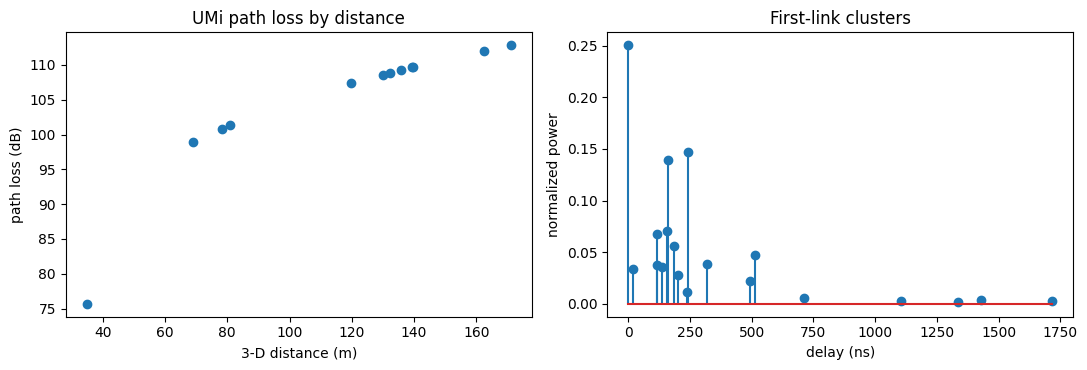

ray tensor: (1, 12, 1, 19, 20) active links: 12


In [4]:
from channel_dataset.channels.wireless import ScenarioRayGenerator

scenario_config = ScenarioConfig("UMi", 3.5e9)
scenario = create_scenario(scenario_config)
large_scale = scenario.sample_large_scale(topology, execution.random_stream(3302))
rays = ScenarioRayGenerator("UMi").generate(topology, large_scale, execution.random_stream(3303))

active_power = torch.where(rays.cluster_mask, rays.powers_linear, 0.0)
link_power = torch.sum(active_power, dim=-1)
assert torch.allclose(link_power[large_scale.link_mask], torch.ones_like(link_power[large_scale.link_mask]), atol=1e-10)
assert rays.shape[-1] == 20

distances = as_numpy(geometry.distance_3d_m[0, :, 0])
losses = as_numpy(large_scale.path_loss_db[0, :, 0])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(distances, losses, c=as_numpy(topology.los_mask[0, :, 0]) if topology.los_mask is not None else "tab:blue")
axes[0].set(title="UMi path loss by distance", xlabel="3-D distance (m)", ylabel="path loss (dB)")
cluster_mask = as_numpy(rays.cluster_mask[0, 0, 0]).astype(bool)
axes[1].stem(as_numpy(rays.delays_s[0, 0, 0])[cluster_mask] * 1e9, as_numpy(rays.powers_linear[0, 0, 0])[cluster_mask])
axes[1].set(title="First-link clusters", xlabel="delay (ns)", ylabel="normalized power")
fig.tight_layout()
plt.show()
print("ray tensor:", rays.shape, "active links:", int(torch.sum(large_scale.link_mask)))

## 4. Assemble the system channel and inspect blockage

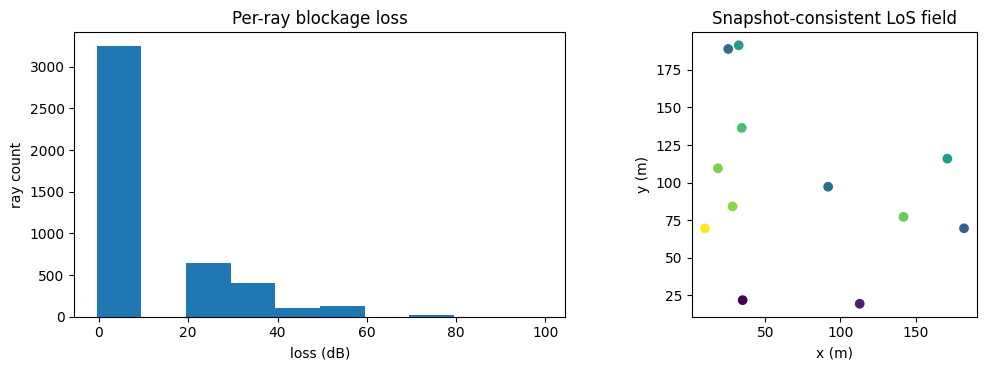

system CIR: (1, 12, 1, 1, 1, 23, 4) OFDM: (1, 12, 1, 1, 1, 4, 16)


In [5]:
from channel_dataset.channels.wireless import (
    NonSelfBlockingModelA,
    SelfBlockingModel,
    SnapshotSpatialConsistency,
    SystemLevelWirelessChannel,
)
from channel_dataset.channels.wireless.antennas import load_antenna_layout
from channel_dataset.channels.wireless.transforms import cir_to_ofdm, subcarrier_frequencies

layout = load_antenna_layout("profiles/wireless/antenna_isotropic_siso.yaml")
system = SystemLevelWirelessChannel(
    scenario_config,
    topology,
    layout,
    layout,
    blockage_models=(SelfBlockingModel("portrait"), NonSelfBlockingModelA("portrait")),
)
result = system.realize_with_diagnostics(request)
response = cir_to_ofdm(result.cir, subcarrier_frequencies(16, 15_000.0, execution))
blockage = result.rays.blockage_loss_db

assert blockage is not None and torch.all(blockage >= 0.0)
assert torch.isfinite(response.coefficients).all()
assert torch.equal(
    result.cir.coefficients,
    system.realize_with_diagnostics(
        ChannelSamplingRequest(1, 4, 2_000.0, execution, execution.random_stream(3301), "umi-system")
    ).cir.coefficients,
)

positions = topology.rx_positions_m[..., :2]
fields = SnapshotSpatialConsistency(50.0).sample(positions, execution.random_stream(3304))
fields_replay = SnapshotSpatialConsistency(50.0).sample(positions, execution.random_stream(3304))
assert torch.equal(fields.los_uniform, fields_replay.los_uniform)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(as_numpy(blockage).ravel(), bins=np.arange(-0.5, float(torch.max(blockage)) + 10.5, 10.0))
axes[0].set(title="Per-ray blockage loss", xlabel="loss (dB)", ylabel="ray count")
axes[1].scatter(as_numpy(positions[0, :, 0]), as_numpy(positions[0, :, 1]), c=as_numpy(fields.los_uniform[0]), cmap="viridis")
axes[1].set(title="Snapshot-consistent LoS field", xlabel="x (m)", ylabel="y (m)", aspect="equal")
fig.tight_layout()
plt.show()
print("system CIR:", result.cir.shape, "OFDM:", response.shape)

## Manual check and next experiments

- Change the scenario and regenerate a topology inside that scenario's applicability range.
- Toggle path loss and shadow fading independently; small-scale stream labels stay stable.
- Compare portrait and landscape self-blocking angular regions.
- Increase receiver density and inspect how snapshot field correlation decays with distance.